Runtime
→ Change runtime type
→ Hardware accelerator
→ GPU

In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [3]:
!git clone https://github.com/facebookresearch/sam2.git
%cd /content/sam2
!pip install -e ".[notebooks]"

Cloning into 'sam2'...
remote: Enumerating objects: 1107, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 1107 (delta 13), reused 7 (delta 7), pack-reused 1089 (from 2)
Receiving objects: 100% (1107/1107), 134.85 MiB | 28.59 MiB/s, done.
Resolving deltas: 100% (385/385), done.
/content/sam2
Obtaining file:///content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 17.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 7

In [4]:
import sam2

print("SAM2 imported successfully")

SAM2 imported successfully


In [5]:
%cd /content/sam2/checkpoints

/content/sam2/checkpoints


In [6]:
!bash download_ckpts.sh

--2026-10-26 20:25:07--  https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_tiny.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 65.8.54.65, 65.8.54.85, 65.8.54.33, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|65.8.54.65|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 156008466 (149M) [application/vnd.snesdev-page-table]
Saving to: ‘sam2.1_hiera_tiny.pt’

sam2.1_hiera_tiny.p 100%[===================>] 148.78M   220MB/s    in 0.7s    

2026-10-26 20:25:08 (220 MB/s) - ‘sam2.1_hiera_tiny.pt’ saved [156008466/156008466]

--2026-10-26 20:25:08--  https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 65.8.54.65, 65.8.54.85, 65.8.54.33, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|65.8.54.65|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 184416285 (176M) [application/vnd.snesdev-

In [7]:
!ls -lh
%cd /content/sam2

total 1.5G
-rwxr-xr-x 1 root root 2.6K Oct 26 20:18 download_ckpts.sh
-rw-r--r-- 1 root root 309M Sep 29  2024 sam2.1_hiera_base_plus.pt
-rw-r--r-- 1 root root 857M Sep 29  2024 sam2.1_hiera_large.pt
-rw-r--r-- 1 root root 176M Sep 29  2024 sam2.1_hiera_small.pt
-rw-r--r-- 1 root root 149M Sep 29  2024 sam2.1_hiera_tiny.pt
/content/sam2


In [8]:
import torch
from sam2.build_sam import build_sam2_video_predictor
checkpoint = "/content/sam2/checkpoints/sam2.1_hiera_small.pt"
model_cfg = "configs/sam2.1/sam2.1_hiera_s.yaml"
predictor = build_sam2_video_predictor(
    model_cfg,
    checkpoint,
    device="cuda"
)
print("SAM2 video predictor loaded")


SAM2 video predictor loaded


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
import os

davis_root = "/content/drive/MyDrive/query-image-sam2-data/DAVIS"

os.makedirs(davis_root, exist_ok=True)

print("DAVIS folder exists:", os.path.exists(davis_root))
print("Contents:", os.listdir(davis_root))

DAVIS folder exists: True
Contents: ['README.md', 'SOURCES.md', 'ImageSets', 'Annotations', 'JPEGImages']


In [11]:
print(os.listdir(davis_root))

['README.md', 'SOURCES.md', 'ImageSets', 'Annotations', 'JPEGImages']


In [12]:
import os

davis_root = "/content/drive/MyDrive/query-image-sam2-data/DAVIS"

jpeg_480p = os.path.join(davis_root, "JPEGImages", "480p")
ann_480p = os.path.join(davis_root, "Annotations", "480p")

print("JPEG 480p exists:", os.path.exists(jpeg_480p))
print("Annotation 480p exists:", os.path.exists(ann_480p))

JPEG 480p exists: True
Annotation 480p exists: True


In [13]:
sequences = sorted(os.listdir(jpeg_480p))

print("Number of sequences:", len(sequences))
print("First 10 sequences:", sequences[:10])

Number of sequences: 90
First 10 sequences: ['bear', 'bike-packing', 'blackswan', 'bmx-bumps', 'bmx-trees', 'boat', 'boxing-fisheye', 'breakdance', 'breakdance-flare', 'bus']


In [27]:
sequence_name = "koala"

frame_dir = os.path.join(jpeg_480p, sequence_name)
mask_dir = os.path.join(ann_480p, sequence_name)

print("Frame directory:", frame_dir)
print("Mask directory:", mask_dir)

print("Frame count:", len(os.listdir(frame_dir)))
print("Mask count:", len(os.listdir(mask_dir)))

Frame directory: /content/drive/MyDrive/query-image-sam2-data/DAVIS/JPEGImages/480p/koala
Mask directory: /content/drive/MyDrive/query-image-sam2-data/DAVIS/Annotations/480p/koala
Frame count: 100
Mask count: 100


In [28]:
frame_files = sorted(
    [f for f in os.listdir(frame_dir) if f.endswith(".jpg")]
)

mask_files = sorted(
    [f for f in os.listdir(mask_dir) if f.endswith(".png")]
)

print("First frames:", frame_files[:5])
print("First masks:", mask_files[:5])

First frames: ['00000.jpg', '00001.jpg', '00002.jpg', '00003.jpg', '00004.jpg']
First masks: ['00000.png', '00001.png', '00002.png', '00003.png', '00004.png']


In [29]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

frame_path = os.path.join(frame_dir, "00000.jpg")
mask_path = os.path.join(mask_dir, "00000.png")

frame = Image.open(frame_path)
mask = Image.open(mask_path)

mask_array = np.array(mask)

print("Object IDs:", np.unique(mask_array))

Object IDs: [0 1]


In [30]:
def mask_to_box(mask, object_id=1):
    ys, xs = np.where(mask == object_id)

    if len(xs) == 0 or len(ys) == 0:
        raise ValueError(f"Object ID {object_id} not found in mask")

    x1 = xs.min()
    y1 = ys.min()
    x2 = xs.max()
    y2 = ys.max()

    return [int(x1), int(y1), int(x2), int(y2)]

box = mask_to_box(mask_array, object_id=1)

print("Bounding box:", box)

Bounding box: [0, 32, 853, 479]


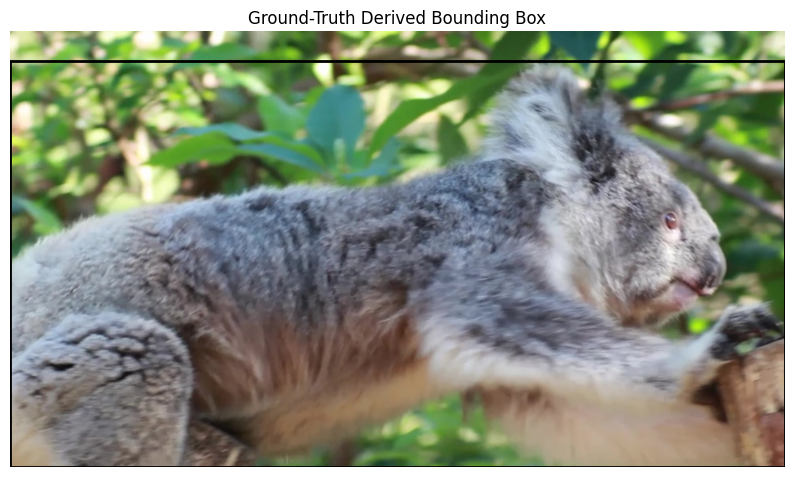

In [24]:
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(10, 6))

ax.imshow(frame)

x1, y1, x2, y2 = box

rect = patches.Rectangle(
    (x1, y1),
    x2 - x1,
    y2 - y1,
    fill=False,
    linewidth=2
)

ax.add_patch(rect)

plt.axis("off")
plt.title("Ground-Truth Derived Bounding Box")
plt.show()

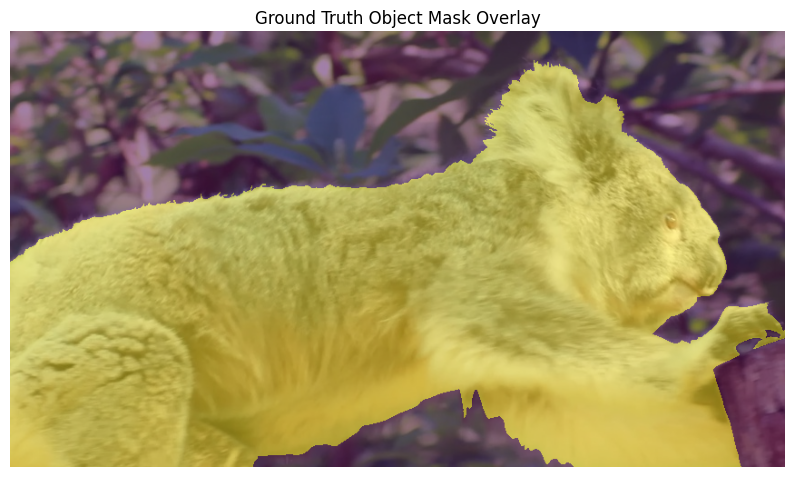

In [25]:
object_mask = (mask_array == 1)

plt.figure(figsize=(10, 6))
plt.imshow(frame)
plt.imshow(object_mask, alpha=0.5)
plt.axis("off")
plt.title("Ground Truth Object Mask Overlay")
plt.show()

In [31]:
print("Image shape:", mask_array.shape)

print(
    "Object pixels:",
    np.sum(object_mask)
)

print(
    "Percentage of image occupied by object:",
    np.sum(object_mask) / object_mask.size * 100
)

Image shape: (480, 854)
Object pixels: 240743
Percentage of image occupied by object: 58.72926424668228


In [33]:
video_dir = frame_dir

print(video_dir)

inference_state = predictor.init_state(video_path=video_dir)
predictor.reset_state(inference_state)

/content/drive/MyDrive/query-image-sam2-data/DAVIS/JPEGImages/480p/koala


frame loading (JPEG): 100%|██████████| 100/100 [00:04<00:00, 21.47it/s]


In [37]:
ann_frame_idx = 0
ann_obj_id = 1

box_np = np.array(box, dtype=np.float32)

print("Box sent to SAM2:", box_np)

_, out_obj_ids, out_mask_logits = predictor.add_new_points_or_box(
    inference_state=inference_state,
    frame_idx=ann_frame_idx,
    obj_id=ann_obj_id,
    box=box_np,
)

#convert sam2 output into binary mask
sam2_initial_mask = (
    out_mask_logits[0] > 0.0
).cpu().numpy().squeeze()

print("SAM2 mask shape:", sam2_initial_mask.shape)

Box sent to SAM2: [  0.  32. 853. 479.]
SAM2 mask shape: (480, 854)


/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: inputs.is_cuda() INTERNAL ASSERT FAILED at "sam2/csrc/connected_components.cu":215, please report a bug to PyTorch. inputs must be a CUDA tensor
Exception raised from get_connected_componnets at sam2/csrc/connected_components.cu:215 (most recent call first):
frame #0: c10::Error::Error(c10::SourceLocation, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >) + 0x9d (0x7b9d1597305d in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #1: c10::detail::torchCheckFail(char const*, char const*, unsigned int, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > const&) + 0xc3 (0x7b9d159076fd in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #2: c10::detail::torchInternalAssertFail(char const*, char const*, unsigned int, char const*, char const*) + 0x42 (0x7b9d1596f6a2 in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #3: 

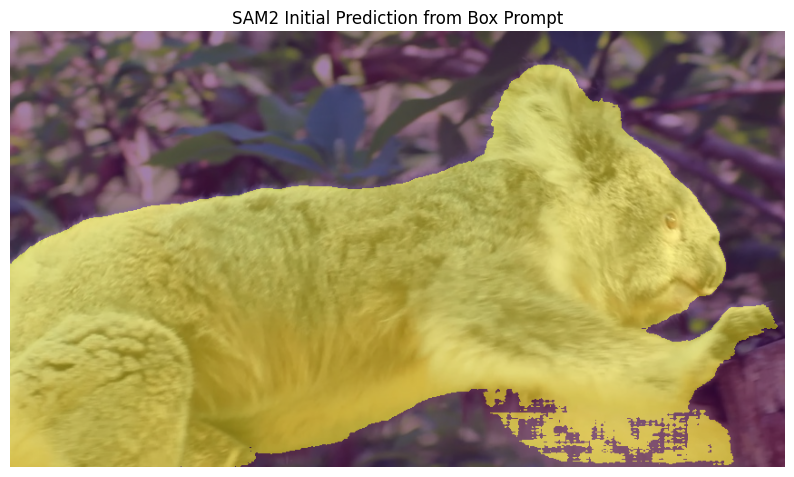

In [38]:
plt.figure(figsize=(10, 6))
plt.imshow(frame)
plt.imshow(sam2_initial_mask, alpha=0.5)
plt.axis("off")
plt.title("SAM2 Initial Prediction from Box Prompt")
plt.show()

In [39]:
gt_object_mask = (mask_array == 1)

intersection = np.logical_and(
    sam2_initial_mask,
    gt_object_mask
).sum()

union = np.logical_or(
    sam2_initial_mask,
    gt_object_mask
).sum()

initial_iou = intersection / union

print("Initial frame IoU:", initial_iou)

Initial frame IoU: 0.9566411151557317


In [40]:
#temporal propagation across the full video sequence.
video_segments = {}

for out_frame_idx, out_obj_ids, out_mask_logits in predictor.propagate_in_video(
    inference_state
):
    video_segments[out_frame_idx] = {
        out_obj_id: (out_mask_logits[i] > 0.0).cpu().numpy().squeeze()
        for i, out_obj_id in enumerate(out_obj_ids)
    }

print("Tracked frames:", len(video_segments))

propagate in video:   0%|          | 0/100 [00:00<?, ?it/s]/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: inputs.is_cuda() INTERNAL ASSERT FAILED at "sam2/csrc/connected_components.cu":215, please report a bug to PyTorch. inputs must be a CUDA tensor
Exception raised from get_connected_componnets at sam2/csrc/connected_components.cu:215 (most recent call first):
frame #0: c10::Error::Error(c10::SourceLocation, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >) + 0x9d (0x7b9d1597305d in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #1: c10::detail::torchCheckFail(char const*, char const*, unsigned int, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > const&) + 0xc3 (0x7b9d159076fd in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #2: c10::detail::torchInternalAssertFail(char const*, char const*, unsigned int, char const*, char const*) + 0x42 (0x7b9d1596f6a2 in /usr/local/l

Tracked frames: 100


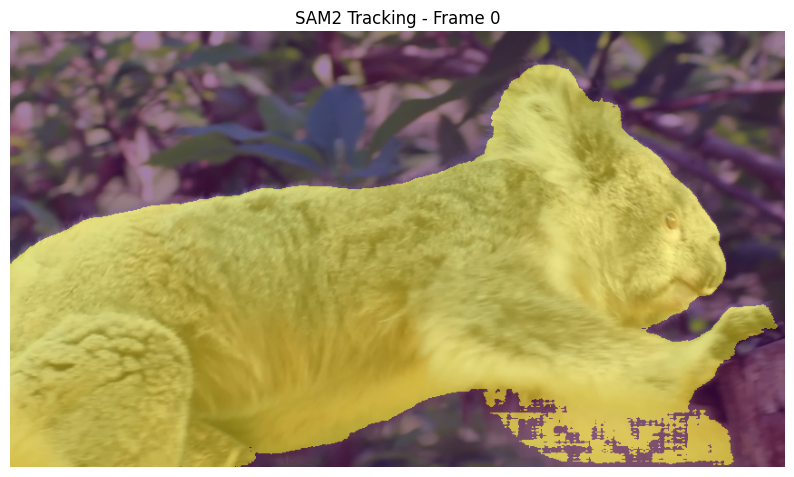

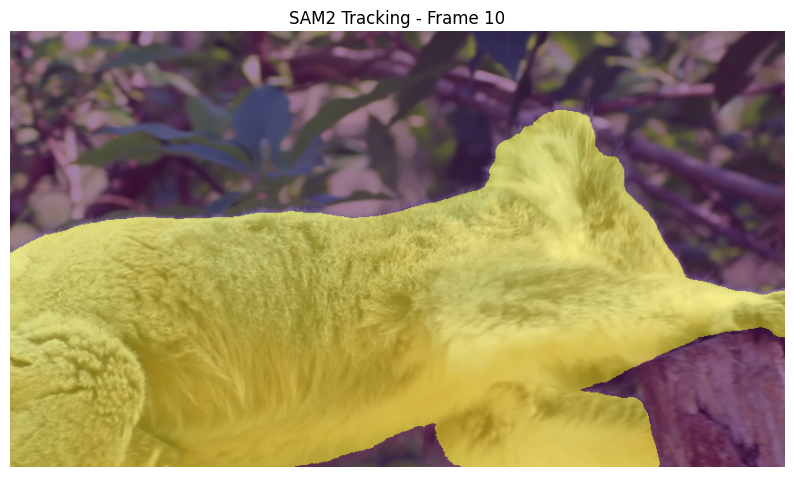

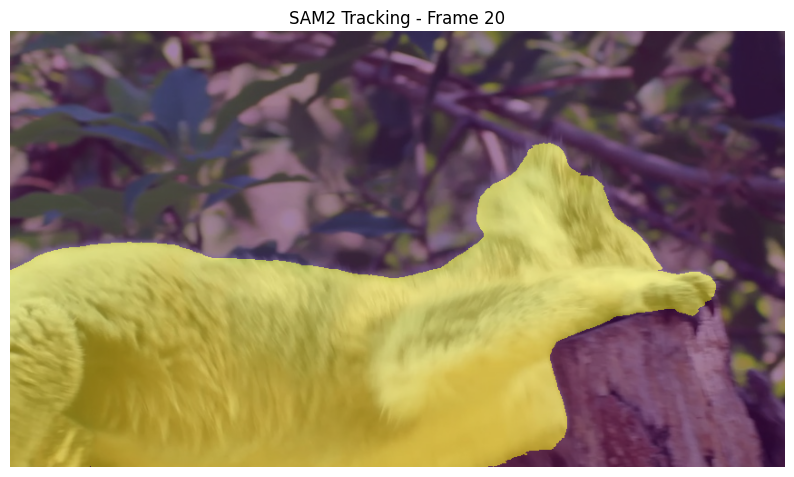

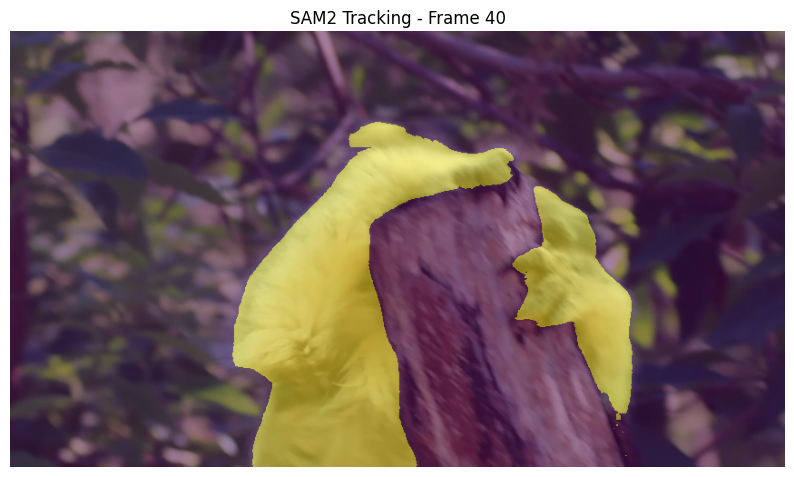

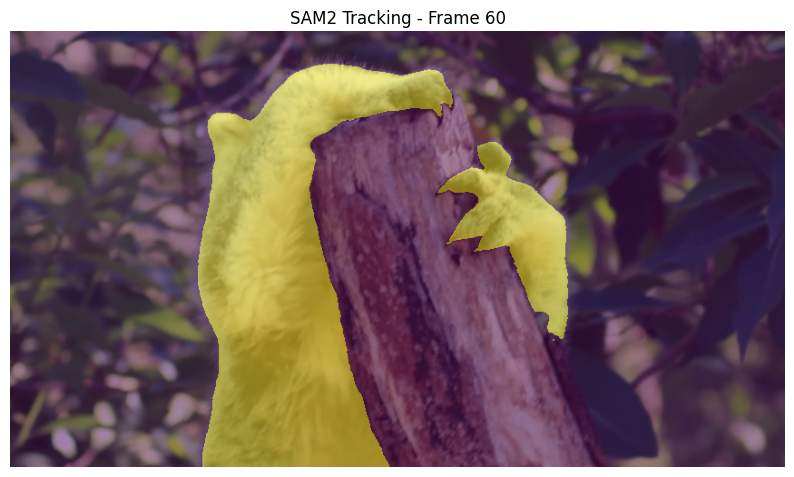

In [41]:
#inspecting few frames
test_frames = [0, 10, 20, 40, 60]

for frame_idx in test_frames:
    frame_path = os.path.join(
        frame_dir,
        f"{frame_idx:05d}.jpg"
    )

    frame_img = Image.open(frame_path)

    pred_mask = video_segments[frame_idx][ann_obj_id]

    plt.figure(figsize=(10, 6))
    plt.imshow(frame_img)
    plt.imshow(pred_mask, alpha=0.5)
    plt.axis("off")
    plt.title(f"SAM2 Tracking - Frame {frame_idx}")
    plt.show()

In [44]:
#evaluate tracking over all frames
j_scores = []

for frame_idx in sorted(video_segments.keys()):

    pred_mask = video_segments[frame_idx][ann_obj_id]

    gt_path = os.path.join(
        mask_dir,
        f"{frame_idx:05d}.png"
    )

    gt_mask = np.array(Image.open(gt_path)) == 1

    intersection = np.logical_and(
        pred_mask,
        gt_mask
    ).sum()

    union = np.logical_or(
        pred_mask,
        gt_mask
    ).sum()

    if union == 0:
        iou = 1.0
    else:
        iou = intersection / union

    j_scores.append(iou)

    mean_j = np.mean(j_scores)

print("Number of evaluated frames:", len(j_scores))
print("Mean J / IoU:", mean_j)

print("Minimum J:", np.min(j_scores))
print("Maximum J:", np.max(j_scores))

worst_frame = int(np.argmin(j_scores))

print("Worst frame:", worst_frame)
print("Worst-frame J:", j_scores[worst_frame])



Number of evaluated frames: 100
Mean J / IoU: 0.9473567634188421
Minimum J: 0.908573382340371
Maximum J: 0.9822529904609248
Worst frame: 86
Worst-frame J: 0.908573382340371


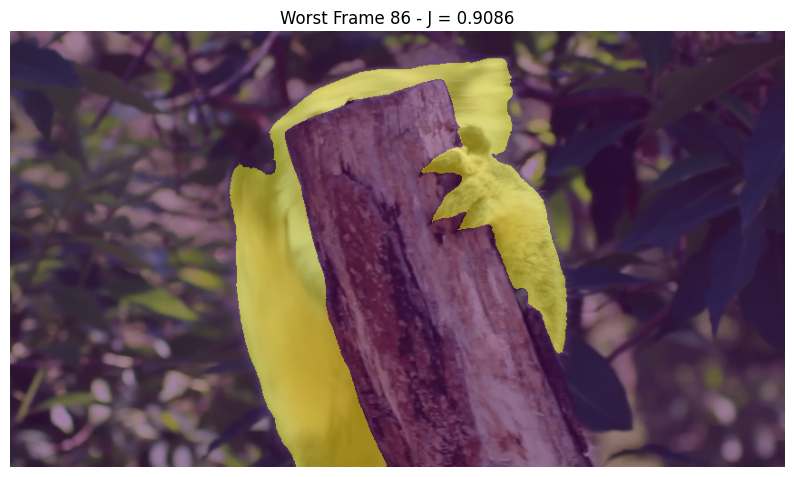

In [45]:
#inspecting the worst frame
worst_frame = int(np.argmin(j_scores))

worst_frame_path = os.path.join(
    frame_dir,
    f"{worst_frame:05d}.jpg"
)

worst_gt_path = os.path.join(
    mask_dir,
    f"{worst_frame:05d}.png"
)

worst_img = Image.open(worst_frame_path)
worst_gt = np.array(Image.open(worst_gt_path)) == 1
worst_pred = video_segments[worst_frame][ann_obj_id]

plt.figure(figsize=(10, 6))
plt.imshow(worst_img)
plt.imshow(worst_pred, alpha=0.5)
plt.axis("off")
plt.title(
    f"Worst Frame {worst_frame} - J = {j_scores[worst_frame]:.4f}"
)
plt.show()

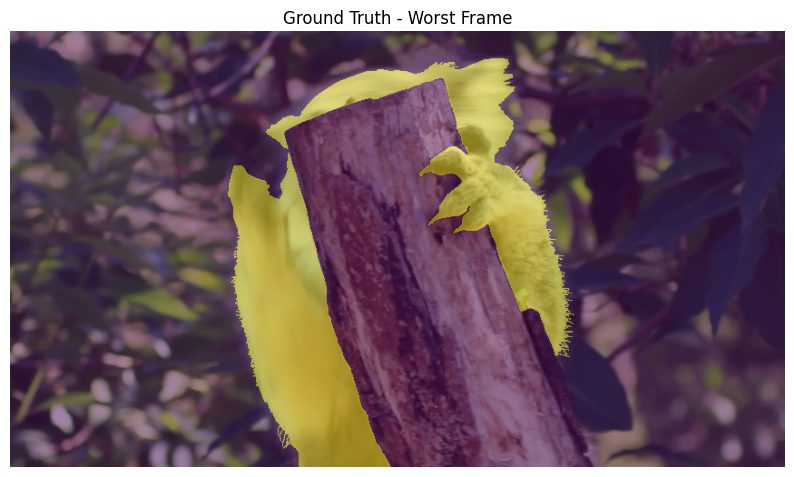

In [46]:
plt.figure(figsize=(10, 6))
plt.imshow(worst_img)
plt.imshow(worst_gt, alpha=0.5)
plt.axis("off")
plt.title("Ground Truth - Worst Frame")
plt.show()

In [47]:
!pip install scipy scikit-image


In [48]:
import numpy as np
from scipy.ndimage import binary_dilation
from skimage.segmentation import find_boundaries

In [49]:
def boundary_f_score(pred_mask, gt_mask, tolerance=2):
    pred_mask = pred_mask.astype(bool)
    gt_mask = gt_mask.astype(bool)

    pred_boundary = find_boundaries(pred_mask, mode="outer")
    gt_boundary = find_boundaries(gt_mask, mode="outer")

    pred_dilated = binary_dilation(pred_boundary, iterations=tolerance)
    gt_dilated = binary_dilation(gt_boundary, iterations=tolerance)

    pred_match = np.logical_and(pred_boundary, gt_dilated).sum()
    gt_match = np.logical_and(gt_boundary, pred_dilated).sum()

    pred_count = pred_boundary.sum()
    gt_count = gt_boundary.sum()

    if pred_count == 0 and gt_count == 0:
        return 1.0

    if pred_count == 0 or gt_count == 0:
        return 0.0

    precision = pred_match / pred_count
    recall = gt_match / gt_count

    if precision + recall == 0:
        return 0.0

    f_score = 2 * precision * recall / (precision + recall)

    return f_score

In [50]:
f_scores = []

for frame_idx in sorted(video_segments.keys()):

    pred_mask = video_segments[frame_idx][ann_obj_id]

    gt_path = os.path.join(
        mask_dir,
        f"{frame_idx:05d}.png"
    )

    gt_mask = np.array(Image.open(gt_path)) == 1

    f = boundary_f_score(
        pred_mask,
        gt_mask
    )

    f_scores.append(f)

In [52]:
mean_f = np.mean(f_scores)

print("Mean F:", mean_f)
print("Minimum F:", np.min(f_scores))
print("Maximum F:", np.max(f_scores))

j_and_f = (mean_j + mean_f) / 2

print("Mean J:", mean_j)
print("Mean F:", mean_f)
print("J&F:", j_and_f)

Mean F: 0.6384879720188475
Minimum F: 0.4567329374482456
Maximum F: 0.761900199750148
Mean J: 0.9473567634188421
Mean F: 0.6384879720188475
J&F: 0.7929223677188448


In [53]:
#Tracking FPs
predictor.reset_state(inference_state)
_, out_obj_ids, out_mask_logits = predictor.add_new_points_or_box(
    inference_state=inference_state,
    frame_idx=ann_frame_idx,
    obj_id=ann_obj_id,
    box=box_np,
)


/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: inputs.is_cuda() INTERNAL ASSERT FAILED at "sam2/csrc/connected_components.cu":215, please report a bug to PyTorch. inputs must be a CUDA tensor
Exception raised from get_connected_componnets at sam2/csrc/connected_components.cu:215 (most recent call first):
frame #0: c10::Error::Error(c10::SourceLocation, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >) + 0x9d (0x7b9d1597305d in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #1: c10::detail::torchCheckFail(char const*, char const*, unsigned int, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > const&) + 0xc3 (0x7b9d159076fd in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #2: c10::detail::torchInternalAssertFail(char const*, char const*, unsigned int, char const*, char const*) + 0x42 (0x7b9d1596f6a2 in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #3: 

In [54]:
import time
torch.cuda.synchronize()
start_time = time.time()

timed_video_segments = {}

for out_frame_idx, out_obj_ids, out_mask_logits in predictor.propagate_in_video(
    inference_state
):
    timed_video_segments[out_frame_idx] = {
        out_obj_id: (out_mask_logits[i] > 0.0).cpu().numpy().squeeze()
        for i, out_obj_id in enumerate(out_obj_ids)
    }

propagate in video:   0%|          | 0/100 [00:00<?, ?it/s]/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: inputs.is_cuda() INTERNAL ASSERT FAILED at "sam2/csrc/connected_components.cu":215, please report a bug to PyTorch. inputs must be a CUDA tensor
Exception raised from get_connected_componnets at sam2/csrc/connected_components.cu:215 (most recent call first):
frame #0: c10::Error::Error(c10::SourceLocation, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >) + 0x9d (0x7b9d1597305d in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #1: c10::detail::torchCheckFail(char const*, char const*, unsigned int, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > const&) + 0xc3 (0x7b9d159076fd in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #2: c10::detail::torchInternalAssertFail(char const*, char const*, unsigned int, char const*, char const*) + 0x42 (0x7b9d1596f6a2 in /usr/local/l

In [55]:
torch.cuda.synchronize()
end_time = time.time()

propagation_time = end_time - start_time
num_tracked_frames = len(timed_video_segments)

tracking_fps = num_tracked_frames / propagation_time

print("Tracked frames:", num_tracked_frames)
print("Propagation time:", propagation_time, "seconds")
print("Tracking FPS:", tracking_fps)

Tracked frames: 100
Propagation time: 50.71583676338196 seconds
Tracking FPS: 1.9717706811494902


In [56]:
#Saving the result in CSV

import pandas as pd

baseline_result = pd.DataFrame([{
    "sequence": sequence_name,
    "initialization": "ground_truth_derived_box",
    "frames": len(video_segments),
    "initial_iou": initial_iou,
    "mean_j": mean_j,
    "mean_f": mean_f,
    "j_and_f": j_and_f,
    "tracking_fps": tracking_fps,
    "propagation_time_sec": propagation_time
}])

baseline_result

,sequence,initialization,frames,initial_iou,mean_j,mean_f,j_and_f,tracking_fps,propagation_time_sec
0,koala,ground_truth_derived_box,100,0.956641,0.947357,0.638488,0.792922,1.971771,50.715837


In [57]:
results_path = "/content/drive/MyDrive/query-image-sam2-data/baseline_results.csv"

baseline_result.to_csv(results_path, index=False)

print("Saved to:", results_path)

Saved to: /content/drive/MyDrive/query-image-sam2-data/baseline_results.csv
